# Laboratorio de clasificación 3

|                |   |
:----------------|---|
| **Nombre**     | Cecilia Quiroz Hidalgo  |
| **Fecha**      | 16/10/2026  |
| **Expediente** | 757942  | 

Una regresión logística simple toma **P** predictores y usa una función no lineal para convertir la respuesta binaria **Y** en probabilidades entre $0$ y $1$.

La visualización de este escenario es puntos separados por una línea recta.

<center><img src="https://wirelesspi.com/wp-content/uploads/2022/08/figure-logistic-regression-decision-boundary-2-570x550.png"></center>

Para casos donde los datos no son linealmente separables usamos el truco del kernel para mapear los datos a un espacio de Hilbert.

Imagina un escenario donde tienes dos predictores $x_1, x_2$ y la salida de estos predictores se comporta de esta manera:

| **$x_1$** | **$x_2$** | Salida |
:-----------|-----------|--------|
| 0         | 0         | 0      |
| 0         | 1         | 1      |
| 1         | 0         | 1      |
| 1         | 1         | 0      |


Imagínalo como el interruptos de luz de un foco en una escalera. Se puede prender y apagar desde arriba y desde abajo.

<center><img src="https://www.researchgate.net/profile/Brian-Spears/publication/322048911/figure/fig4/AS:667820685807618@1536232267250/The-exclusive-or-XOR-function-is-a-nonlinear-function-that-returns-0-when-its-two.png"></center>

¿Cómo podemos separar estos datos usando sólo regresión logística? Sin importar cómo usemos una sola línea, nunca se van a poder separar todos los casos, por lo que tendríamos situaciones donde siempre habría error. 

Solución: ¿Por qué nos estamos limitando a una sola línea?

<center><img src="https://pabloinsente.github.io/assets/post-5/XOR-linear.png"></center>

**La regresión logística sola es un método de aprendizaje estadístico convexo. Combinar dos regresiones logísticas para clasificar datos no linealmente separables convierte el problema a uno no convexo. ¿Por qué?**

La función de error de una sola regresión logística tiene una sola solución mínima, por lo que es fácil encontrar el mejor resultado. Al combinar dos regresiones logísticas, los pesos y las funciones sigmoides hacen que la función de error tenga varios valles. Además hay simetría, intercambiar las neuronas ocultas puede dar el mismo resultado. Esto genera soluciones iguales en distintos puntos, por lo que el problema deja de ser convexo.

**¿Qué significa que una función sea convexa?**

Una función es convexa cuando la línea recta que une dos puntos de su gráfica queda por encima o sobre la curva.

**¿Por qué nos importa que una función sea convexa o no? ¿Qué impacto tiene para los resultados?**

- Si es convexa: es más fácil encontrar la mejor solución y obtener resultados similares en cada entrenamiento.
- Si no es convexa: el algoritmo puede encontrar una solución que no sea la mejor. Los resultados pueden cambiar según el punto de inicio y los hiperparámetros.

Impacto en los resultados: las redes neuronales pueden dar resultados diferentes en cada entrenamiento. Sin embargo, al no ser convexas, pueden aprender patrones más complejos, como separar datos que no se pueden dividir con una línea recta

## Ejercicio 1

Utilizaremos el clasificador `MLPClassifier` de la librería `sklearn`.

Entra a la documentación y describe cómo funciona este objeto (qué entradas necesita, qué salidas da, descripción de sus hiperparámetros).

`MLPClassifier` es un perceptrón multicapa, una red neuronal con una capa de entrada, una o más capas ocultas y una capa de salida. Se entrena con retropropagación minimizando la log-loss.

**Entradas**
- `fit(X, y)`: `X` es una matriz numérica (filas = observaciones, columnas = variables) e `y` las etiquetas. Las variables deben ser numéricas  y conviene escalarlas, porque la red es sensible a la escala.

**Salidas**
- `predict(X)`: la clase predicha.
- `predict_proba(X)`: la probabilidad de cada clase.
- `score(X, y)`: el accuracy.
- Atributos útiles tras entrenar: `coefs_` (pesos), `intercepts_` (sesgos), `loss_` (error final), `loss_curve_` (error por época), `n_iter_` (iteraciones usadas).

**Hiperparámetros principales**

- **`hidden_layer_sizes`**: cuántas capas ocultas tiene la red y cuántas neuronas lleva cada una. Por ejemplo, `(50, 20)` son 2 capas, una de 50 neuronas y otra de 20. Default: `(100,)`.
- **`activation`**: la función que usa cada neurona para transformar su resultado (`relu`, `tanh`, `logistic` o `identity`). Default: `relu`.
- **`solver`**: el método que usa la red para aprender, es decir, para ajustar los pesos (`adam`, `sgd` o `lbfgs`). Default: `adam`.
- **`alpha`**: qué tanto se "castiga" a la red para que no se aprenda los datos de memoria. Entre más alto, más simple es el modelo. Default: `0.0001`.
- **`batch_size`**: cuántos datos revisa la red antes de corregir sus pesos. Default: 200.
- **`learning_rate_init`**: qué tan grandes son los pasos con los que aprende. Si son muy grandes, la red se puede pasar de la solución; si son muy chicos, aprende lento. Default: `0.001`.
- **`learning_rate`**: si el tamaño del paso se mantiene igual o va cambiando. Sólo aplica con `sgd`. Default: `constant`.
- **`max_iter`**: cuántas veces, como máximo, la red recorre todos los datos para aprender. Default: `200`.
- **`early_stopping`**: si se activa, la red deja de entrenar cuando ya no mejora. Default: `False`.
- **`random_state`**: una semilla que hace que el resultado salga igual cada vez que corres el código. Default: `None`.

## Ejercicio 2

Utiliza el objeto de perceptrón multicapa para clasificar si un tumor es maligno o benigno con el dataset `Brain Tumor Dataset`. Utiliza un cross-validation de train-test de 70/30. Sigue todos los pasos de EDA y limpieza vistos.

### Carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn import metrics
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("brain_tumor_dataset.csv")
df.head()

,Patient_ID,Age,Gender,Tumor_Type,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,1,73,Male,Malignant,5.375612,Temporal,Astrocytoma,III,Vision Issues,Seizures,Seizures,No,No,No,51.312579,0.111876,No,Positive,Yes
1,2,26,Male,Benign,4.847098,Parietal,Glioblastoma,II,Headache,Headache,Nausea,Yes,Yes,Yes,46.373273,2.165736,Yes,Positive,Yes
2,3,31,Male,Benign,5.588391,Parietal,Meningioma,I,Vision Issues,Headache,Seizures,No,No,No,47.072221,1.884228,No,Negative,No
3,4,29,Male,Malignant,1.436600,Temporal,Medulloblastoma,IV,Vision Issues,Seizures,Headache,Yes,No,Yes,51.853634,1.283342,Yes,Negative,No
4,5,54,Female,Benign,2.417506,Parietal,Glioblastoma,I,Headache,Headache,Seizures,No,No,Yes,54.708987,2.069477,No,Positive,Yes


### EDA

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           20000 non-null  int64  
 1   Age                  20000 non-null  int64  
 2   Gender               20000 non-null  object 
 3   Tumor_Type           20000 non-null  object 
 4   Tumor_Size           20000 non-null  float64
 5   Location             20000 non-null  object 
 6   Histology            20000 non-null  object 
 7   Stage                20000 non-null  object 
 8   Symptom_1            20000 non-null  object 
 9   Symptom_2            20000 non-null  object 
 10  Symptom_3            20000 non-null  object 
 11  Radiation_Treatment  20000 non-null  object 
 12  Surgery_Performed    20000 non-null  object 
 13  Chemotherapy         20000 non-null  object 
 14  Survival_Rate        20000 non-null  float64
 15  Tumor_Growth_Rate    20000 non-null 

In [4]:
df.shape

(20000, 19)

In [5]:
df.describe()

,Patient_ID,Age,Tumor_Size,Survival_Rate,Tumor_Growth_Rate
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,49.433700,5.236552,70.131699,1.547701
std,5773.647028,17.389296,2.754359,17.270834,0.835995
min,1.000000,20.000000,0.500410,40.002386,0.100017
25%,5000.750000,34.000000,2.836686,55.224439,0.830433
50%,10000.500000,49.000000,5.200675,70.305066,1.541821
75%,15000.250000,65.000000,7.624299,85.043395,2.262484
max,20000.000000,79.000000,9.999420,99.998125,2.999835


In [6]:
for col in df.select_dtypes(include="object").columns:
    print(col, "->", df[col].unique())

Gender -> ['Male' 'Female']
Tumor_Type -> ['Malignant' 'Benign']
Location -> ['Temporal' 'Parietal' 'Frontal' 'Occipital']
Histology -> ['Astrocytoma' 'Glioblastoma' 'Meningioma' 'Medulloblastoma']
Stage -> ['III' 'II' 'I' 'IV']
Symptom_1 -> ['Vision Issues' 'Headache' 'Seizures' 'Nausea']
Symptom_2 -> ['Seizures' 'Headache' 'Vision Issues' 'Nausea']
Symptom_3 -> ['Seizures' 'Nausea' 'Headache' 'Vision Issues']
Radiation_Treatment -> ['No' 'Yes']
Surgery_Performed -> ['No' 'Yes']
Chemotherapy -> ['No' 'Yes']
Family_History -> ['No' 'Yes']
MRI_Result -> ['Positive' 'Negative']
Follow_Up_Required -> ['Yes' 'No']


In [9]:
df.isnull().sum()

Patient_ID             0
Age                    0
Gender                 0
Tumor_Type             0
Tumor_Size             0
Location               0
Histology              0
Stage                  0
Symptom_1              0
Symptom_2              0
Symptom_3              0
Radiation_Treatment    0
Surgery_Performed      0
Chemotherapy           0
Survival_Rate          0
Tumor_Growth_Rate      0
Family_History         0
MRI_Result             0
Follow_Up_Required     0
dtype: int64

In [11]:
df = df.drop(columns=["Patient_ID"])

### Codificación, split 70/30 y escalamiento

In [14]:
y = (df["Tumor_Type"] == "Malignant").astype(int)
X = df.drop(columns=["Tumor_Type"])

X = pd.get_dummies(X, drop_first=True, dtype=int)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (14000, 29)  Test: (6000, 29)


### 2.6 Modelo base con `MLPClassifier`

In [18]:
modelo = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
prob = modelo.predict_proba(X_test)[:, 1]

print("Accuracy :", round(metrics.accuracy_score(y_test, pred), 4))
print("Precision:", round(metrics.precision_score(y_test, pred), 4))
print("Recall   :", round(metrics.recall_score(y_test, pred), 4))
print("F1       :", round(metrics.f1_score(y_test, pred), 4))
print("ROC AUC  :", round(metrics.roc_auc_score(y_test, prob), 4))
print()
print(metrics.classification_report(y_test, pred, target_names=["Benigno", "Maligno"]))

Accuracy : 0.499
Precision: 0.5005
Recall   : 0.5105
F1       : 0.5054
ROC AUC  : 0.4947

              precision    recall  f1-score   support

     Benigno       0.50      0.49      0.49      2991
     Maligno       0.50      0.51      0.51      3009

    accuracy                           0.50      6000
   macro avg       0.50      0.50      0.50      6000
weighted avg       0.50      0.50      0.50      6000



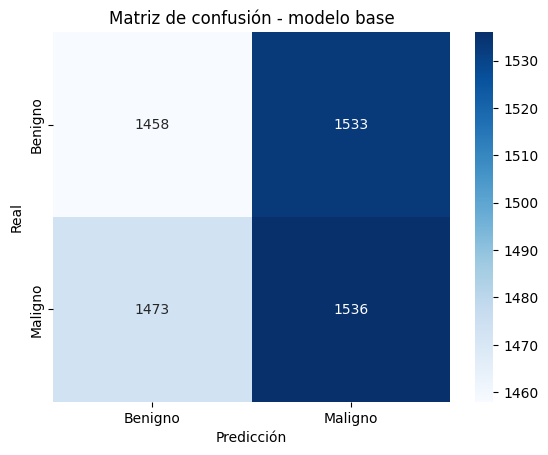

In [19]:
sns.heatmap(metrics.confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - modelo base")
plt.show()

**Observaciones del modelo base:**

- Accuracy = 50% y ROC AUC = 0.49: el modelo prácticamente adivina al azar y no logra distinguir entre tumores benignos y malignos.
- Recall = 0.51: detectó 1,536 de los 3,009 tumores malignos, pero dejó pasar 1,473. Esto es grave porque son falsos negativos.
- Precision = 0.50: de los 3,069 casos que clasificó como malignos, 1,533 eran benignos (falsas alarmas).
- Matriz de confusión: los errores están repartidos de forma similar, lo que indica que el modelo no logra identificar un patrón claro.

El problema probablemente está en los datos y no en el código. Probar distintos hiperparámetros podría mejorar ligeramente los resultados, pero si los datos no contienen patrones útiles, la red neuronal no podrá aprender a distinguir los tumores.

¿Qué métrico crees que sea mejor para este ejercicio? Escoge los 3 métricos que crees más apropiados para esta predicción, argumenta en pro y en contra del top 3. Elige uno para optimizar (justifica tu respuesta).

**Top 3 métricas**

1. **Recall**
   - A favor: en medicina el error más grave es el falso negativo (decirle a alguien que su tumor es benigno cuando es maligno), porque retrasa el tratamiento. El recall mide justo eso.
   - En contra: se puede decir que todo es malignoo, lo que genera muchas falsas alarmas, estudios y angustia innecesarios. Por eso hay que vigilarlo junto con otra métrica.

2. **F1-score**
   - A favor: equilibra detectar malignos (recall) con no dar falsas alarmas (precisión) en un solo número.
   - En contra: le da el mismo peso a ambos errores, cuando en este caso un falso negativo es más grave que un falso positivo. Además es menos intuitivo de explicar.

3. **ROC AUC**
   - A favor: sirve para comparar modelos de forma justa y luego elegir el umbral que convenga clínicamente.
   - En contra: es un resumen global, un AUC alto no dice cuántos malignos se escapan con el umbral que realmente se va a usar.

**Métrica a optimizar: Recall.** 

El costo de no detectar un tumor maligno es mucho mayor que el de una falsa alarma (que se corrige con estudios adicionales). Para evitar eso de predecir todo como maligno, en el Ejercicio 3 se reporta también la precisión y el F1 como control.

## Ejercicio 3

Modifica los hiperparámetros para elevar el métrico elegido. Intenta con 10 sets de hiperparámetros distintos. Crea una tabla que muestre los resultados.

In [20]:
configs = [
    {"hidden_layer_sizes": (100,),        "activation": "relu",     "solver": "adam",  "alpha": 0.0001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (50,),         "activation": "relu",     "solver": "adam",  "alpha": 0.0001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (200,),        "activation": "relu",     "solver": "adam",  "alpha": 0.001,  "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (100, 50),     "activation": "relu",     "solver": "adam",  "alpha": 0.0001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (64, 32, 16),  "activation": "relu",     "solver": "adam",  "alpha": 0.01,   "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (100,),        "activation": "tanh",     "solver": "adam",  "alpha": 0.0001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (100,),        "activation": "logistic", "solver": "adam",  "alpha": 0.0001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (100,),        "activation": "relu",     "solver": "sgd",   "alpha": 0.0001, "learning_rate_init": 0.01},
    {"hidden_layer_sizes": (10,),         "activation": "logistic", "solver": "adam",  "alpha": 1.0,    "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (50, 50),      "activation": "tanh",     "solver": "adam",  "alpha": 0.1,    "learning_rate_init": 0.01},
]

resultados = []
for i, p in enumerate(configs, start=1):
    m = MLPClassifier(**p, max_iter=300, random_state=42)
    m.fit(X_train, y_train)
    pr = m.predict(X_test)
    resultados.append({
        "Set": i,
        "Capas": str(p["hidden_layer_sizes"]),
        "Activación": p["activation"],
        "Solver": p["solver"],
        "alpha": p["alpha"],
        "lr_init": p["learning_rate_init"],
        "Recall": round(metrics.recall_score(y_test, pr), 4),
        "Precision": round(metrics.precision_score(y_test, pr), 4),
        "F1": round(metrics.f1_score(y_test, pr), 4),
        "Accuracy": round(metrics.accuracy_score(y_test, pr), 4),
    })

tabla = pd.DataFrame(resultados)
tabla

,Set,Capas,Activación,Solver,alpha,lr_init,Recall,Precision,F1,Accuracy
0,1,"(100,)",relu,adam,0.0001,0.001,0.5105,0.5005,0.5054,0.4990
1,2,"(50,)",relu,adam,0.0001,0.001,0.5158,0.5055,0.5106,0.5042
2,3,"(200,)",relu,adam,0.0010,0.001,0.4633,0.4950,0.4786,0.4938
3,4,"(100, 50)",relu,adam,0.0001,0.001,0.5052,0.5041,0.5046,0.5027
4,5,"(64, 32, 16)",relu,adam,0.0100,0.001,0.5101,0.5002,0.5051,0.4987
5,6,"(100,)",tanh,adam,0.0001,0.001,0.5085,0.5045,0.5065,0.5030
6,7,"(100,)",logistic,adam,0.0001,0.001,0.4666,0.5004,0.4829,0.4988
7,8,"(100,)",relu,sgd,0.0001,0.010,0.5105,0.5028,0.5066,0.5013
8,9,"(10,)",logistic,adam,1.0000,0.001,0.4826,0.4951,0.4887,0.4937
9,10,"(50, 50)",tanh,adam,0.1000,0.010,0.6072,0.5048,0.5513,0.5043


In [21]:
tabla.sort_values("Recall", ascending=False).reset_index(drop=True)

,Set,Capas,Activación,Solver,alpha,lr_init,Recall,Precision,F1,Accuracy
0,10,"(50, 50)",tanh,adam,0.1000,0.010,0.6072,0.5048,0.5513,0.5043
1,2,"(50,)",relu,adam,0.0001,0.001,0.5158,0.5055,0.5106,0.5042
2,1,"(100,)",relu,adam,0.0001,0.001,0.5105,0.5005,0.5054,0.4990
3,8,"(100,)",relu,sgd,0.0001,0.010,0.5105,0.5028,0.5066,0.5013
4,5,"(64, 32, 16)",relu,adam,0.0100,0.001,0.5101,0.5002,0.5051,0.4987
5,6,"(100,)",tanh,adam,0.0001,0.001,0.5085,0.5045,0.5065,0.5030
6,4,"(100, 50)",relu,adam,0.0001,0.001,0.5052,0.5041,0.5046,0.5027
7,9,"(10,)",logistic,adam,1.0000,0.001,0.4826,0.4951,0.4887,0.4937
8,7,"(100,)",logistic,adam,0.0001,0.001,0.4666,0.5004,0.4829,0.4988
9,3,"(200,)",relu,adam,0.0010,0.001,0.4633,0.4950,0.4786,0.4938


In [22]:
mejor = tabla.loc[tabla["Recall"].idxmax()]
print("Mejor set según Recall:")
print(mejor)

Mejor set según Recall:
Set                 10
Capas         (50, 50)
Activación        tanh
Solver            adam
alpha              0.1
lr_init           0.01
Recall          0.6072
Precision       0.5048
F1              0.5513
Accuracy        0.5043
Name: 9, dtype: object


**Conclusión:** 

- El Set 10 fue el mejor en recall, con 0.607 frente a 0.511 del modelo base. Es decir, logró detectar más tumores malignos.
- Sin embargo, la precisión y el accuracy siguieron cerca del 50%, así que el modelo sigue teniendo dificultades para distinguir entre tumores benignos y malignos.
- Los otros 9 sets tuvieron resultados muy parecidos al modelo base. Cambiar los hiperparámetros no mejoró realmente el modelo.

En general, ninguna configuración logró superar claramente el azar. Si se tuviera que elegir alguno, sería el Set 10, porque obtuvo el mayor recall y el mejor F1, auqnue esto no asegura que sea un buen modelo para distinguir los tumores. 